# Chapter 11: Novelty and Outlier Detection

## 1. Ringkasan Bab
Deteksi anomali memegang peranan krusial dalam menjaga integritas data dan mengidentifikasi kejadian langka yang berpotensi berbahaya (seperti penipuan transaksi, intrusi jaringan, atau kerusakan mesin pabrik). Bab ini membahas dua ranah utama pemisahan data tidak lazim:
- **Outlier Detection vs. Novelty Detection**:
  - *Outlier Detection*: Mengidentifikasi data pencilan (*anomali*) yang sudah ada di dalam data latih mentah tanpa asumsi data tersebut bersih.
  - *Novelty Detection*: Melatih model pada data latih yang sepenuhnya bersih (*inliers*) untuk mendeteksi apakah data uji baru bersifat baru/anomali.
- **Isolation Forest (`IsolationForest`)**: Algoritma ansambel berbasis partisi pohon acak yang mengisolasi anomali dengan asumsi titik pencilan memerlukan lebih sedikit percabangan untuk terpisah.
- **One-Class SVM (`OneClassSVM`)**: Metode estimasi batas pendukung (*support vector*) yang membatasi wilayah data reguler pada ruang berdimensi tinggi.
- **Local Outlier Factor (`LocalOutlierFactor`)**: Pengukuran derajat keanehan titik berdasarkan deviasi kepadatan lokal terhadap tetangga-tetangganya.
- **Penanganan dan Evaluasi**: Penggunaan parameter kontaminasi (*contamination*), evaluasi skor anomali, serta visualisasi batas kontur keputusan deteksi.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.inspection import DecisionBoundaryDisplay
import warnings

np.random.seed(2024)
warnings.filterwarnings('ignore')

print("Modul dan dependensi Chapter 11 berhasil dimuat.")

Modul dan dependensi Chapter 11 berhasil dimuat.


## 2. Pembuatan Dataset Sintetis dengan Pencilan (Outliers)

Untuk membandingkan performa algoritma deteksi, dibuat dataset sintetis 2 dimensi:
1. **Inliers**: Dua klaster utama data normal berbasis sebaran Gaussian (`make_blobs`).
2. **Outliers**: Titik-titik pencilan seragam (*uniform noise*) yang disebarkan di luar batas klaster reguler.

Total Sampel Data : 340
Jumlah Inliers    : 300
Jumlah Outliers   : 40 (Rasio kontaminasi: 11.76%)


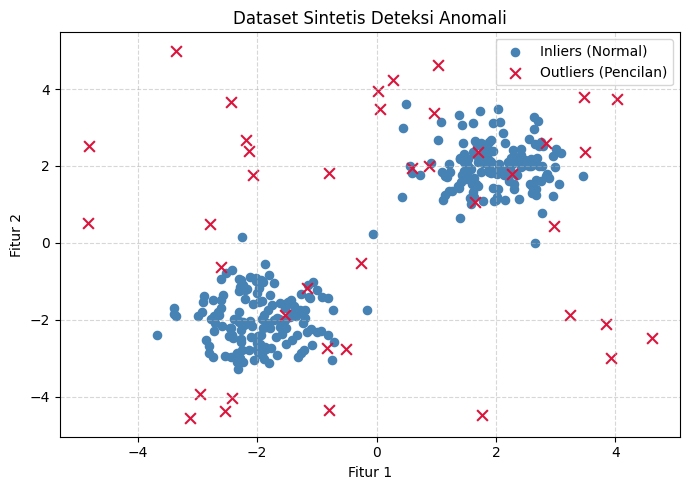

In [7]:
# 1. Menghasilkan Data Normal (Inliers)
X_inliers, _ = make_blobs(n_samples=300, centers=[[2, 2], [-2, -2]], cluster_std=0.6, random_state=2024)

# 2. Menghasilkan Data Pencilan (Outliers)
X_outliers = np.random.uniform(low=-5, high=5, size=(40, 2))

# Menggabungkan Data
X_synthetic = np.vstack([X_inliers, X_outliers])
ground_truth = np.ones(len(X_synthetic), dtype=int)
ground_truth[len(X_inliers):] = -1  # Label -1 menandakan outlier

print(f"Total Sampel Data : {X_synthetic.shape[0]}")
print(f"Jumlah Inliers    : {len(X_inliers)}")
print(f"Jumlah Outliers   : {len(X_outliers)} (Rasio kontaminasi: {len(X_outliers)/len(X_synthetic):.2%})")

# Visualisasi Data Mentah
plt.figure(figsize=(7, 5))
plt.scatter(X_inliers[:, 0], X_inliers[:, 1], c='steelblue', s=35, label='Inliers (Normal)')
plt.scatter(X_outliers[:, 0], X_outliers[:, 1], c='crimson', marker='x', s=60, label='Outliers (Pencilan)')
plt.title('Dataset Sintetis Deteksi Anomali', fontsize=12)
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 3. Isolation Forest

`IsolationForest` memisahkan observasi dengan memilih fitur secara acak dan memotong nilai split secara acak antara nilai minimum dan maksimum fitur tersebut:
- Karena data anomali memiliki nilai fitur ekstrem atau berada di area sepi, anomali memerlukan **kedalaman pohon (*path length*) yang lebih pendek** untuk terisolasi dibandingkan titik normal.
- Parameter `contamination`: Perkiraan proporsi pencilan di dalam dataset yang digunakan sebagai batas nilai ambang keputusan.
- Konvensi label output scikit-learn:
  - `1`: Inlier (Data Normal)
  - `-1`: Outlier / Anomali

In [8]:
# Inisialisasi dan Pelatihan Isolation Forest
iso_forest = IsolationForest(contamination=0.12, random_state=2024)
pred_iso = iso_forest.fit_predict(X_synthetic)

# Perhitungan Skor Anomali (semakin negatif nilainya, semakin besar kemungkinan anomali)
anomaly_scores_iso = iso_forest.decision_function(X_synthetic)

print("=== Hasil Deteksi Isolation Forest ===")
print(f"Jumlah Terdeteksi Inlier (1) : {np.sum(pred_iso == 1)}")
print(f"Jumlah Terdeteksi Outlier (-1): {np.sum(pred_iso == -1)}")

=== Hasil Deteksi Isolation Forest ===
Jumlah Terdeteksi Inlier (1) : 299
Jumlah Terdeteksi Outlier (-1): 41


## 4. One-Class SVM

`OneClassSVM` adalah algoritma yang mempelajari batas keputusan yang membungkus sebagian besar data pada ruang fitur berdimensi tinggi menggunakan fungsi kernel (umumnya RBF):
- Merupakan pilihan utama untuk **Novelty Detection**, di mana data pelatihan diasumsikan tidak terkontaminasi oleh anomali eksternal.
- Parameter `nu` ($\nu$): Mengontrol batas atas proporsi kesalahan pelatihan (*training errors*) dan batas bawah jumlah vektor pendukung (*support vectors*).

In [9]:
# Inisialisasi dan Pelatihan One-Class SVM
oc_svm = OneClassSVM(kernel='rbf', gamma=0.1, nu=0.12)
pred_oc_svm = oc_svm.fit_predict(X_synthetic)

print("=== Hasil Deteksi One-Class SVM ===")
print(f"Jumlah Terdeteksi Inlier (1) : {np.sum(pred_oc_svm == 1)}")
print(f"Jumlah Terdeteksi Outlier (-1): {np.sum(pred_oc_svm == -1)}")

=== Hasil Deteksi One-Class SVM ===
Jumlah Terdeteksi Inlier (1) : 297
Jumlah Terdeteksi Outlier (-1): 43


## 5. Local Outlier Factor (LOF)

`LocalOutlierFactor` menghitung skor anomali berdasarkan kepadatan lokal suatu titik dibandingkan dengan tetangga-tetangganya ($k$-nearest neighbors):
- Titik yang kepadatannya jauh lebih rendah dibandingkan kepadatan tetangga di sekitarnya diidentifikasi sebagai pencilan (*local outlier*).
- Sangat efektif pada dataset yang memiliki klaster dengan kerapatan atau densitas yang bervariasi.

In [12]:
# Inisialisasi dan Prediksi Local Outlier Factor
# Mode novelty=False digunakan khusus untuk Outlier Detection
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.12)
pred_lof = lof.fit_predict(X_synthetic)

# Skor faktor densitas lokal negatif
negative_outlier_factor = lof.negative_outlier_factor_

print("=== Hasil Deteksi Local Outlier Factor (LOF) ===")
print(f"Jumlah Terdeteksi Inlier (1) : {np.sum(pred_lof == 1)}")
print(f"Jumlah Terdeteksi Outlier (-1): {np.sum(pred_lof == -1)}")

=== Hasil Deteksi Local Outlier Factor (LOF) ===
Jumlah Terdeteksi Inlier (1) : 299
Jumlah Terdeteksi Outlier (-1): 41


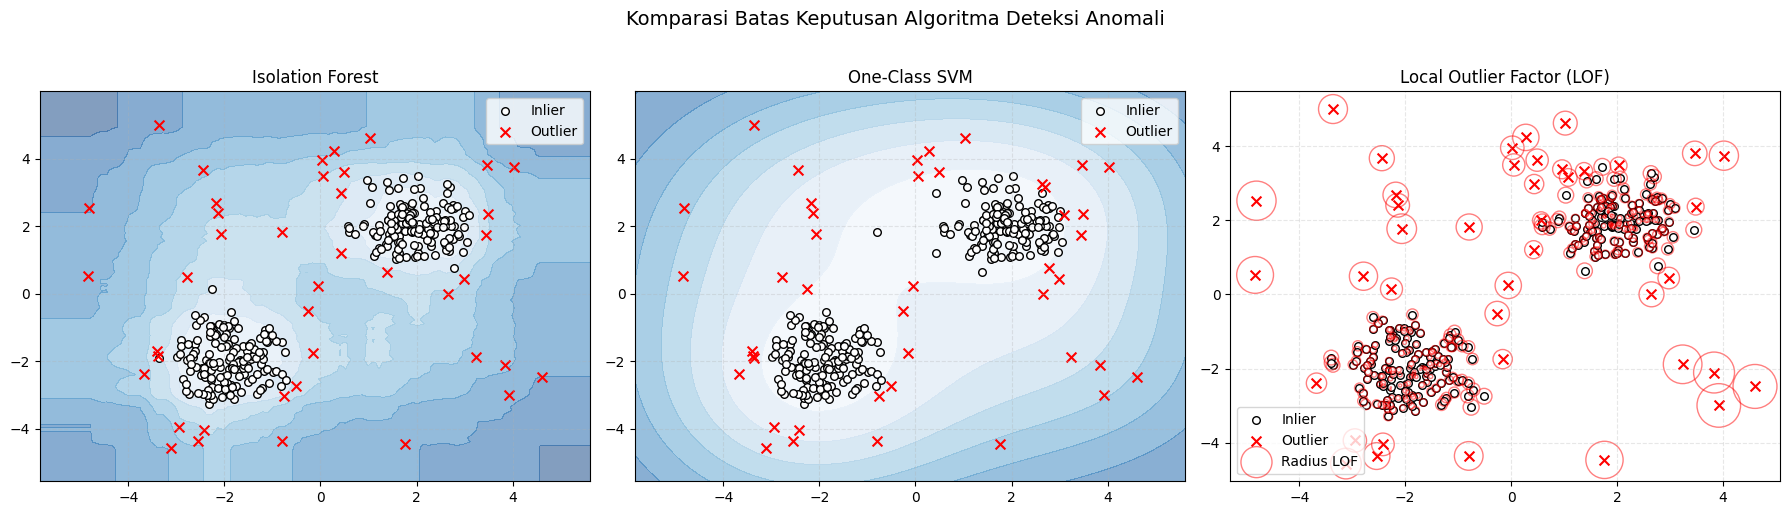

In [11]:
# Komparasi Visual Kontur Batas Keputusan Deteksi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Plot Isolation Forest
DecisionBoundaryDisplay.from_estimator(
    iso_forest, X_synthetic, response_method="decision_function",
    plot_method="contourf", cmap=plt.cm.Blues_r, alpha=0.5, ax=axes[0]
)
axes[0].scatter(X_synthetic[pred_iso == 1, 0], X_synthetic[pred_iso == 1, 1], c='white', edgecolors='k', s=30, label='Inlier')
axes[0].scatter(X_synthetic[pred_iso == -1, 0], X_synthetic[pred_iso == -1, 1], c='red', marker='x', s=50, label='Outlier')
axes[0].set_title('Isolation Forest', fontsize=12)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.3)

# 2. Plot One-Class SVM
DecisionBoundaryDisplay.from_estimator(
    oc_svm, X_synthetic, response_method="decision_function",
    plot_method="contourf", cmap=plt.cm.Blues_r, alpha=0.5, ax=axes[1]
)
axes[1].scatter(X_synthetic[pred_oc_svm == 1, 0], X_synthetic[pred_oc_svm == 1, 1], c='white', edgecolors='k', s=30, label='Inlier')
axes[1].scatter(X_synthetic[pred_oc_svm == -1, 0], X_synthetic[pred_oc_svm == -1, 1], c='red', marker='x', s=50, label='Outlier')
axes[1].set_title('One-Class SVM', fontsize=12)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.3)

# 3. Plot Local Outlier Factor
axes[2].scatter(X_synthetic[pred_lof == 1, 0], X_synthetic[pred_lof == 1, 1], c='white', edgecolors='k', s=30, label='Inlier')
axes[2].scatter(X_synthetic[pred_lof == -1, 0], X_synthetic[pred_lof == -1, 1], c='red', marker='x', s=50, label='Outlier')
# Visualisasi radius keparahan pencilan LOF
radius = (negative_outlier_factor.max() - negative_outlier_factor) / (negative_outlier_factor.max() - negative_outlier_factor.min())
axes[2].scatter(X_synthetic[:, 0], X_synthetic[:, 1], s=1000 * radius, edgecolors='r', facecolors='none', alpha=0.5, label='Radius LOF')
axes[2].set_title('Local Outlier Factor (LOF)', fontsize=12)
axes[2].legend(loc='lower left')
axes[2].grid(True, linestyle='--', alpha=0.3)

plt.suptitle('Komparasi Batas Keputusan Algoritma Deteksi Anomali', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 6. Ringkasan Pedoman Pemilihan Algoritma

| Parameter | Isolation Forest | One-Class SVM | Local Outlier Factor (LOF) |
| :--- | :--- | :--- | :--- |
| **Kategori Deteksi** | Outlier & Novelty | Terutama Novelty | Terutama Outlier |
| **Basis Teori** | Partisi pohon acak | Pemaksimalan margin pembungkus | Kepadatan kerapatan lokal k-NN |
| **Skalabilitas Data** | Sangat cepat $O(n)$ | Menengah pada dimensi tinggi | Lambat pada dataset besar $O(n^2)$ |
| **Bentuk Distribusi** | Bebas asumsi bentuk | Baik untuk struktur data padat | Unggul pada klaster multi-densitas |
| **Prediksi Data Baru** | Ya (`.predict()`) | Ya (`.predict()`) | Hanya jika `novelty=True` |

## 7. Analisis dan Kesimpulan
1. **Efisiensi Partisi Isolation Forest**: Isolation Forest menunjukkan kemampuan terbaik dalam membatasi wilayah normal secara seimbang tanpa bergantung pada penghitungan matriks jarak pasangan yang mahal.
2. **Karakteristik Pembungkus One-Class SVM**: One-Class SVM membentuk batas amplop ketat di sekitar data padat, menjadikannya opsi paling aman untuk menyaring data baru yang menyimpang dari distribusi murni.
3. **Kepekaan Lokal LOF**: Analisis lingkaran radius LOF berhasil mendeteksi titik yang terisolasi dari pusat kepadatan lokal tanpa terdistorsi oleh perbedaan kepadatan antar dua klaster data normal.